<a href="https://colab.research.google.com/github/Sravan05nani/Energy-Aware-Adaptive-IoT/blob/main/notebooks/energy_aware_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import sys
import platform
import os

print("=" * 45)
print("ENERGY-AWARE ADAPTIVE IoT PROJECT")
print("=" * 45)

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)
print("Operating System:", platform.system())
print("Platform:", platform.platform())

print("\nEnvironment verification completed.")

ENERGY-AWARE ADAPTIVE IoT PROJECT
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python Executable: /usr/bin/python3
Operating System: Linux
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

Environment verification completed.


In [5]:
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn

In [6]:
# Numerical computation
import numpy as np

# Data processing
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scientific computing
import scipy

# Machine learning evaluation utilities
import sklearn

print("All libraries imported successfully!")

print("\nInstalled library versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!

Installed library versions:
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
SciPy: 1.16.3
Scikit-learn: 1.6.1


Sensor readings: [25 26 27 26 28 30 29]
Average temperature: 27.285714285714285
Maximum temperature: 30
Minimum temperature: 25

Sensor Data:


,Time,Temperature
0,1,25
1,2,26
2,3,27
3,4,26
4,5,28
5,6,30
6,7,29


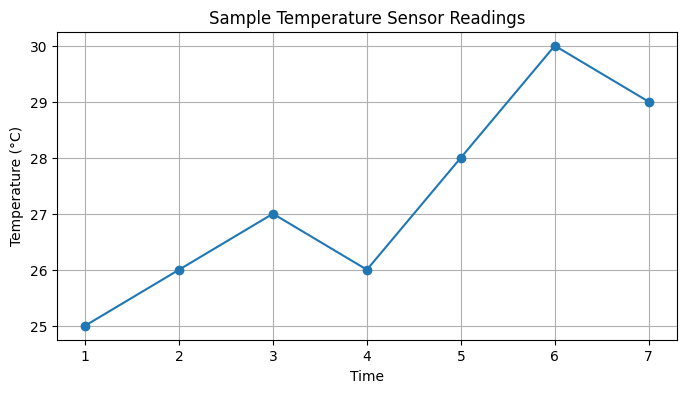

In [7]:
# Test numerical calculations
sensor_values = np.array([25, 26, 27, 26, 28, 30, 29])

print("Sensor readings:", sensor_values)
print("Average temperature:", np.mean(sensor_values))
print("Maximum temperature:", np.max(sensor_values))
print("Minimum temperature:", np.min(sensor_values))

# Test DataFrame creation
data = pd.DataFrame({
    "Time": range(1, 8),
    "Temperature": sensor_values
})

print("\nSensor Data:")
display(data)

# Test graph generation
plt.figure(figsize=(8, 4))

plt.plot(
    data["Time"],
    data["Temperature"],
    marker="o"
)

plt.title("Sample Temperature Sensor Readings")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)

plt.show()


# PHASE 2: SYSTEM ARCHITECTURE AND DESIGN

## 1. Project Objective

To design and simulate an energy-aware adaptive sampling mechanism for IoT sensor networks that dynamically adjusts sampling intervals according to environmental variations.

The objective is to reduce energy consumption while maintaining acceptable environmental monitoring accuracy and event detection performance.

## 2. Proposed System

The proposed system consists of 10 simulated wireless environmental sensor nodes and a central gateway.

Each sensor node monitors temperature and humidity. A sampling controller determines the next sampling interval based on observed environmental variations.

## 3. Sampling Algorithms

### Algorithm 1: Fixed Sampling
Samples are collected at a constant interval of 10 seconds.

### Algorithm 2: Threshold-Based Sampling
The sampling interval is reduced to 1 second when the difference between consecutive observations exceeds a predefined threshold. Otherwise, the interval remains 10 seconds.

### Algorithm 3: Proposed Adaptive Sampling
The sampling interval dynamically changes according to the estimated rate of environmental variation, within a configurable range of 1 to 30 seconds.

## 4. Initial Simulation Parameters

- Number of sensor nodes: 10
- Simulation duration: 3600 seconds
- Ground-truth resolution: 1 second
- Fixed sampling interval: 10 seconds
- Minimum adaptive interval: 1 second
- Maximum adaptive interval: 30 seconds
- Random seed: 42

## 5. Energy Consumption Model

Total energy consumption includes:

- Sensing energy
- Processing energy
- Communication energy
- Idle or sleep energy

All energy values will be calculated using consistent units.

## 6. Performance Evaluation

The algorithms will be compared using:

- Total energy consumption
- Energy savings percentage
- Number of samples
- Mean Absolute Error (MAE)
- Root Mean Square Error (RMSE)
- Event detection delay
- Estimated network lifetime

## 7. Experimental Fairness

All algorithms will use identical environmental input signals, simulation durations, sensor configurations, initial battery capacities and energy model parameters.

Repeated experiments with different random seeds will be conducted to evaluate consistency.

## 8. Simulation Limitations

The initial implementation is a software-based analytical simulation. It does not directly measure physical ESP32 power consumption or simulate a complete wireless communication protocol.


# PHASE 3: ENVIRONMENTAL SENSOR DATA GENERATION

## Objective
Generate realistic synthetic temperature and humidity
time-series data for 10 virtual IoT sensor nodes.

## Dataset components
1. Ground-truth environmental data.
2. Noisy sensor measurement data.
3. Environmental event labels.

## Environmental scenarios
- Stable conditions
- Gradual temperature and humidity changes
- Sudden environmental events
- Oscillating conditions
- Final stable conditions

In [8]:

# =====================================================
# PHASE 3.5: SIMULATION CONFIGURATION
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Network configuration
TOTAL_SENSORS = 10

# Simulation configuration
SIMULATION_DURATION = 3600
TIME_RESOLUTION = 1

# Environmental baseline
BASE_TEMPERATURE = 25.0
BASE_HUMIDITY = 65.0

# Sensor measurement noise
TEMP_NOISE_STD = 0.15
HUMIDITY_NOISE_STD = 0.6

# Sampling configuration
FIXED_INTERVAL = 10
MIN_ADAPTIVE_INTERVAL = 1
MAX_ADAPTIVE_INTERVAL = 30

# Time axis: 0 to 3599 seconds
time = np.arange(
    0,
    SIMULATION_DURATION,
    TIME_RESOLUTION
)

# Verify configuration
print("SIMULATION CONFIGURATION")
print("-" * 40)

print("Total sensors:", TOTAL_SENSORS)
print("Simulation duration:", SIMULATION_DURATION, "seconds")
print("Reference readings:", len(time))
print("Temperature baseline:", BASE_TEMPERATURE, "°C")
print("Humidity baseline:", BASE_HUMIDITY, "%")
print("Random seed:", RANDOM_SEED)

print("\nConfiguration initialized successfully.")


SIMULATION CONFIGURATION
----------------------------------------
Total sensors: 10
Simulation duration: 3600 seconds
Reference readings: 3600
Temperature baseline: 25.0 °C
Humidity baseline: 65.0 %
Random seed: 42

Configuration initialized successfully.


In [9]:

# =====================================================
# PHASE 3.6: TEMPERATURE GROUND-TRUTH GENERATION
# =====================================================

def generate_temperature(time):

    temperature = np.zeros(len(time), dtype=float)

    # Stage 1: Stable conditions (0-600 seconds)
    mask = (time >= 0) & (time < 600)

    temperature[mask] = (
        25.0
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 2: Gradual temperature rise (600-1500)
    mask = (time >= 600) & (time < 1500)

    elapsed = time[mask] - 600

    temperature[mask] = (
        25.0
        + 0.005 * elapsed
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 3: Stable period (1500-2100)
    mask = (time >= 1500) & (time < 2100)

    temperature[mask] = (
        29.5
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 4: Sudden environmental event (2100-2400)
    mask = (time >= 2100) & (time < 2400)

    elapsed = time[mask] - 2100

    temperature[mask] = (
        29.5
        + 0.02 * elapsed
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 5: Oscillating conditions (2400-3000)
    mask = (time >= 2400) & (time < 3000)

    elapsed = time[mask] - 2400

    temperature[mask] = (
        35.5
        + 1.5 * np.sin(2 * np.pi * elapsed / 120)
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    # Stage 6: Final stable conditions (3000-3600)
    mask = (time >= 3000) & (time < 3600)

    temperature[mask] = (
        35.5
        + 0.15 * np.sin(2 * np.pi * time[mask] / 180)
    )

    return temperature

# Generate temperature ground truth
temperature_truth = generate_temperature(time)

print("Temperature ground-truth signal generated.")
print("Number of readings:", len(temperature_truth))
print("Minimum temperature:", round(np.min(temperature_truth), 2), "°C")
print("Maximum temperature:", round(np.max(temperature_truth), 2), "°C")

Temperature ground-truth signal generated.
Number of readings: 3600
Minimum temperature: 24.85 °C
Maximum temperature: 37.13 °C


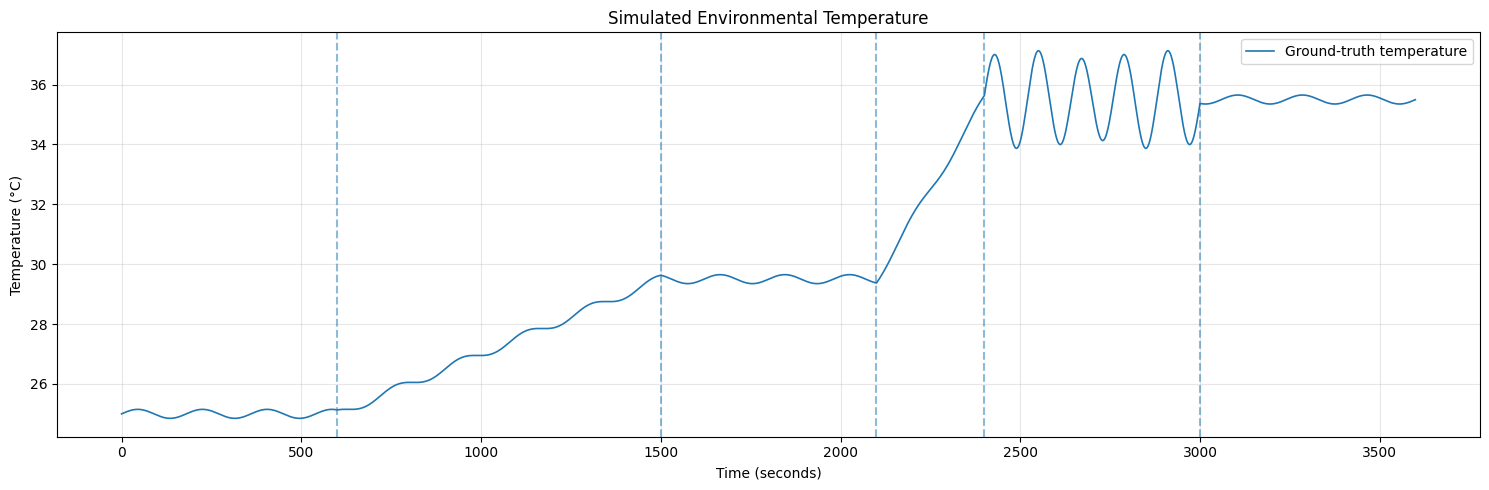

In [10]:

# =====================================================
# TEMPERATURE GROUND-TRUTH VISUALIZATION
# =====================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    temperature_truth,
    linewidth=1.2,
    label="Ground-truth temperature"
)

plt.axvline(600, linestyle="--", alpha=0.5)
plt.axvline(1500, linestyle="--", alpha=0.5)
plt.axvline(2100, linestyle="--", alpha=0.5)
plt.axvline(2400, linestyle="--", alpha=0.5)
plt.axvline(3000, linestyle="--", alpha=0.5)

plt.title("Simulated Environmental Temperature")
plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# =====================================================
# PHASE 3.7: HUMIDITY GROUND-TRUTH GENERATION
# =====================================================

def generate_humidity(time):

    humidity = np.zeros(len(time), dtype=float)

    # Stage 1: Stable conditions
    mask = (time >= 0) & (time < 600)

    humidity[mask] = (
        65.0
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 2: Gradual humidity decrease
    mask = (time >= 600) & (time < 1500)

    elapsed = time[mask] - 600

    humidity[mask] = (
        65.0
        - 0.006 * elapsed
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 3: Stable period
    mask = (time >= 1500) & (time < 2100)

    humidity[mask] = (
        59.6
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 4: Rapid humidity decrease
    mask = (time >= 2100) & (time < 2400)

    elapsed = time[mask] - 2100

    humidity[mask] = (
        59.6
        - 0.02 * elapsed
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 5: Oscillating humidity
    mask = (time >= 2400) & (time < 3000)

    elapsed = time[mask] - 2400

    humidity[mask] = (
        53.6
        + 2.0 * np.sin(2 * np.pi * elapsed / 120)
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    # Stage 6: Final stable period
    mask = (time >= 3000) & (time < 3600)

    humidity[mask] = (
        53.6
        + 0.5 * np.sin(2 * np.pi * time[mask] / 200)
    )

    return humidity

# Generate humidity ground truth
humidity_truth = generate_humidity(time)

print("Humidity ground-truth signal generated.")
print("Number of readings:", len(humidity_truth))
print("Minimum humidity:", round(np.min(humidity_truth), 2), "%")
print("Maximum humidity:", round(np.max(humidity_truth), 2), "%")

Humidity ground-truth signal generated.
Number of readings: 3600
Minimum humidity: 51.19 %
Maximum humidity: 65.5 %


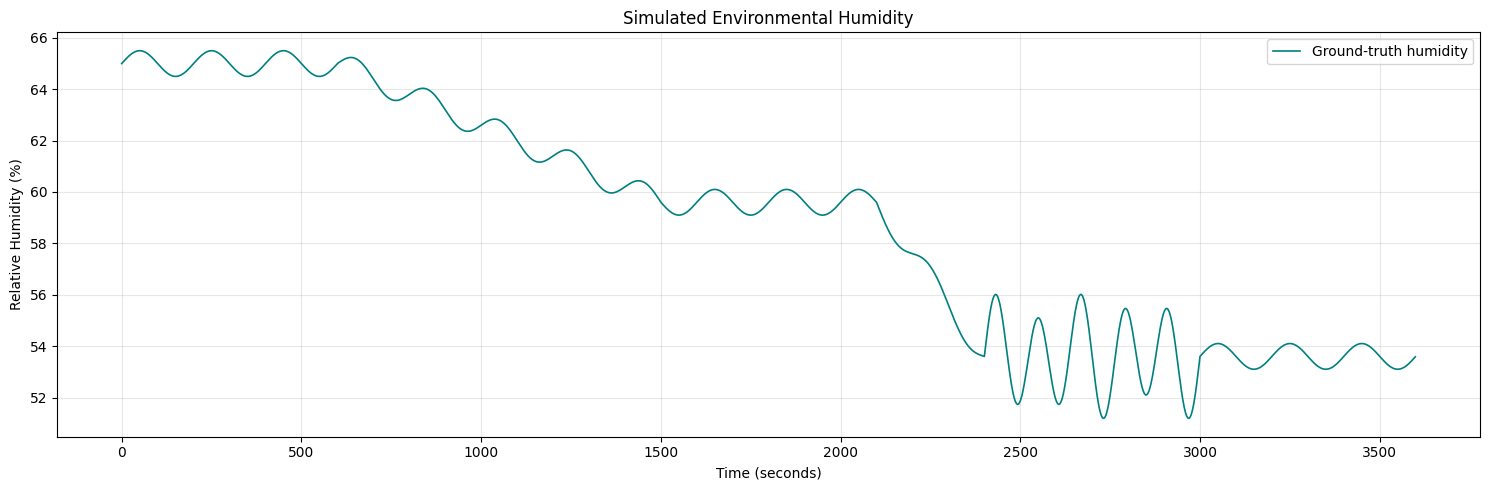

In [12]:

# =====================================================
# HUMIDITY GROUND-TRUTH VISUALIZATION
# =====================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    humidity_truth,
    color="teal",
    linewidth=1.2,
    label="Ground-truth humidity"
)

plt.title("Simulated Environmental Humidity")
plt.xlabel("Time (seconds)")
plt.ylabel("Relative Humidity (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# =====================================================
# PHASE 3.8: GENERATE 10 SENSOR NODE ENVIRONMENTS
# =====================================================

ground_truth_records = []

# Generate individual environmental profiles
for node_id in range(1, TOTAL_SENSORS + 1):

    # Small differences between sensor locations
    temp_offset = rng.normal(0, 0.30)
    humidity_offset = rng.normal(0, 1.00)

    phase = rng.uniform(0, 2 * np.pi)

    # Node-specific slow environmental variation
    local_temp_variation = (
        0.08 * np.sin(
            2 * np.pi * time / 300 + phase
        )
    )

    local_humidity_variation = (
        0.25 * np.sin(
            2 * np.pi * time / 350 + phase
        )
    )

    # Generate node-specific ground truth
    node_temperature = (
        temperature_truth
        + temp_offset
        + local_temp_variation
    )

    node_humidity = (
        humidity_truth
        + humidity_offset
        + local_humidity_variation
    )

    # Keep relative humidity physically valid
    node_humidity = np.clip(node_humidity, 0, 100)

    # Store all readings
    node_data = pd.DataFrame({
        "time_seconds": time,
        "node_id": node_id,
        "temperature_true": node_temperature,
        "humidity_true": node_humidity
    })

    ground_truth_records.append(node_data)

# Combine all nodes into one dataset
ground_truth_df = pd.concat(
    ground_truth_records,
    ignore_index=True
)

print("Ground-truth dataset generated successfully.")

print("Number of sensor nodes:", TOTAL_SENSORS)
print("Total records:", len(ground_truth_df))

display(ground_truth_df.head(10))

Ground-truth dataset generated successfully.
Number of sensor nodes: 10
Total records: 36000


,time_seconds,node_id,temperature_true,humidity_true
0,0,1,25.029327,63.765991
1,1,1,25.035632,63.784558
2,2,1,25.041958,63.803171
3,3,1,25.048297,63.821813
4,4,1,25.054642,63.840469
5,5,1,25.060988,63.859121
6,6,1,25.067326,63.877755
7,7,1,25.073651,63.896352
8,8,1,25.079956,63.914897
9,9,1,25.086233,63.933375


In [14]:

# Compare the average environmental conditions
# across all 10 nodes

node_summary = ground_truth_df.groupby("node_id").agg(
    avg_temperature=("temperature_true", "mean"),
    avg_humidity=("humidity_true", "mean"),
    min_temperature=("temperature_true", "min"),
    max_temperature=("temperature_true", "max")
).round(2)

display(node_summary)


,avg_temperature,avg_humidity,min_temperature,max_temperature
node_id,,,,
1,30.53,57.89,24.89,37.28
2,30.72,56.98,25.07,37.42
3,30.47,58.62,24.81,37.12
4,30.18,59.81,24.55,36.91
5,30.46,60.05,24.82,37.21
6,30.18,59.30,24.51,36.84
7,30.70,58.87,25.04,37.47
8,30.23,60.15,24.61,36.98
9,30.31,58.57,24.68,37.07


In [15]:

# =====================================================
# PHASE 3.9: SENSOR MEASUREMENT NOISE
# =====================================================

sensor_measurements_df = ground_truth_df.copy()

# Add independent measurement noise
sensor_measurements_df["temperature_measured"] = (
    sensor_measurements_df["temperature_true"]
    + rng.normal(
        0,
        TEMP_NOISE_STD,
        len(sensor_measurements_df)
    )
)

sensor_measurements_df["humidity_measured"] = (
    sensor_measurements_df["humidity_true"]
    + rng.normal(
        0,
        HUMIDITY_NOISE_STD,
        len(sensor_measurements_df)
    )
)

# Keep measured humidity within physical limits
sensor_measurements_df["humidity_measured"] = np.clip(
    sensor_measurements_df["humidity_measured"],
    0,
    100
)

print("Noisy sensor measurements generated.")

print(
    "Total sensor measurement records:",
    len(sensor_measurements_df)
)

display(
    sensor_measurements_df[
        [
            "time_seconds",
            "node_id",
            "temperature_true",
            "temperature_measured",
            "humidity_true",
            "humidity_measured"
        ]
    ].head(10)
)


Noisy sensor measurements generated.
Total sensor measurement records: 36000


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured
0,0,1,25.029327,25.350574,63.765991,63.151837
1,1,1,25.035632,24.974670,63.784558,64.474635
2,2,1,25.041958,24.965121,63.803171,62.912562
3,3,1,25.048297,24.926231,63.821813,63.315618
4,4,1,25.054642,25.147039,63.840469,62.862989
5,5,1,25.060988,25.230334,63.859121,64.110908
6,6,1,25.067326,25.050234,63.877755,63.623430
7,7,1,25.073651,24.947628,63.896352,64.307908
8,8,1,25.079956,24.956283,63.914897,63.329543
9,9,1,25.086233,25.183822,63.933375,64.252260


In [16]:

# =====================================================
# PHASE 3.10: ENVIRONMENTAL SCENARIO LABELING
# =====================================================

def classify_environment(t):

    if t < 600:
        return "Stable"

    elif t < 1500:
        return "Gradual Change"

    elif t < 2100:
        return "Stable"

    elif t < 2400:
        return "Rapid Event"

    elif t < 3000:
        return "Oscillating"

    else:
        return "Stable"

# Add scenario labels
sensor_measurements_df["scenario"] = (
    sensor_measurements_df["time_seconds"]
    .apply(classify_environment)
)

# Add binary event labels
sensor_measurements_df["event_active"] = (
    (
        sensor_measurements_df["time_seconds"] >= 2100
    )
    &
    (
        sensor_measurements_df["time_seconds"] < 2400
    )
).astype(int)

# Display scenario distribution
scenario_summary = (
    sensor_measurements_df
    .groupby("scenario")
    .agg(
        record_count=("time_seconds", "count"),
        event_records=("event_active", "sum")
    )
)

display(scenario_summary)

print("\nScenario labeling completed.")

,record_count,event_records
scenario,,
Gradual Change,9000,0
Oscillating,6000,0
Rapid Event,3000,3000
Stable,18000,0



Scenario labeling completed.


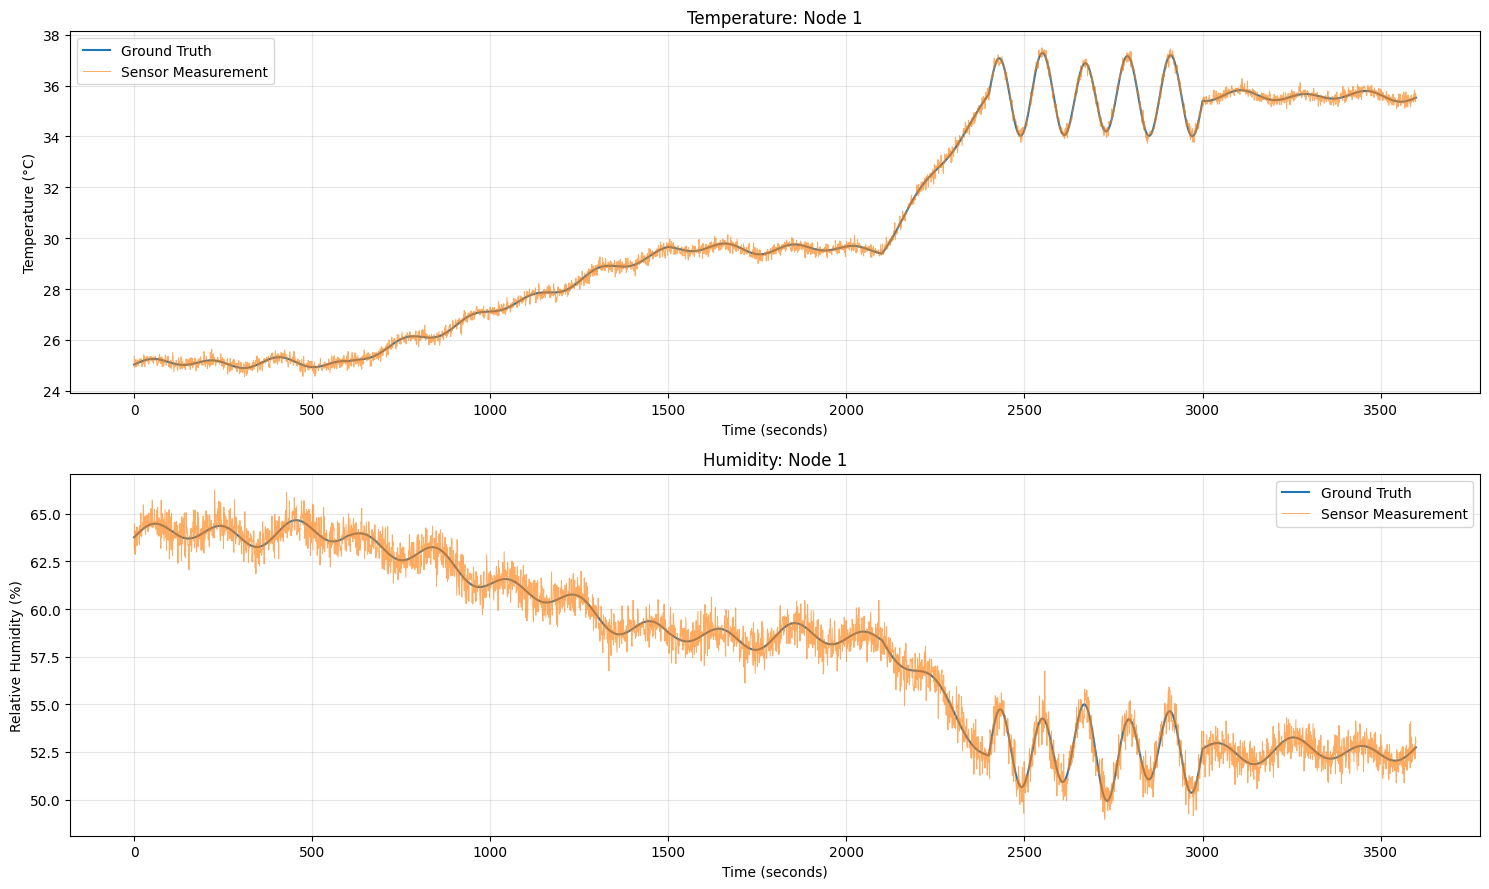

In [17]:

# =====================================================
# PHASE 3.11: COMPLETE DATASET VISUALIZATION
# =====================================================

NODE_TO_VISUALIZE = 1

node_data = sensor_measurements_df[
    sensor_measurements_df["node_id"] == NODE_TO_VISUALIZE
]

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Temperature
axes[0].plot(
    node_data["time_seconds"],
    node_data["temperature_true"],
    label="Ground Truth",
    linewidth=1.5
)

axes[0].plot(
    node_data["time_seconds"],
    node_data["temperature_measured"],
    label="Sensor Measurement",
    alpha=0.65,
    linewidth=0.7
)

axes[0].set_title("Temperature: Node 1")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Humidity
axes[1].plot(
    node_data["time_seconds"],
    node_data["humidity_true"],
    label="Ground Truth",
    linewidth=1.5
)

axes[1].plot(
    node_data["time_seconds"],
    node_data["humidity_measured"],
    label="Sensor Measurement",
    alpha=0.65,
    linewidth=0.7
)

axes[1].set_title("Humidity: Node 1")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Relative Humidity (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


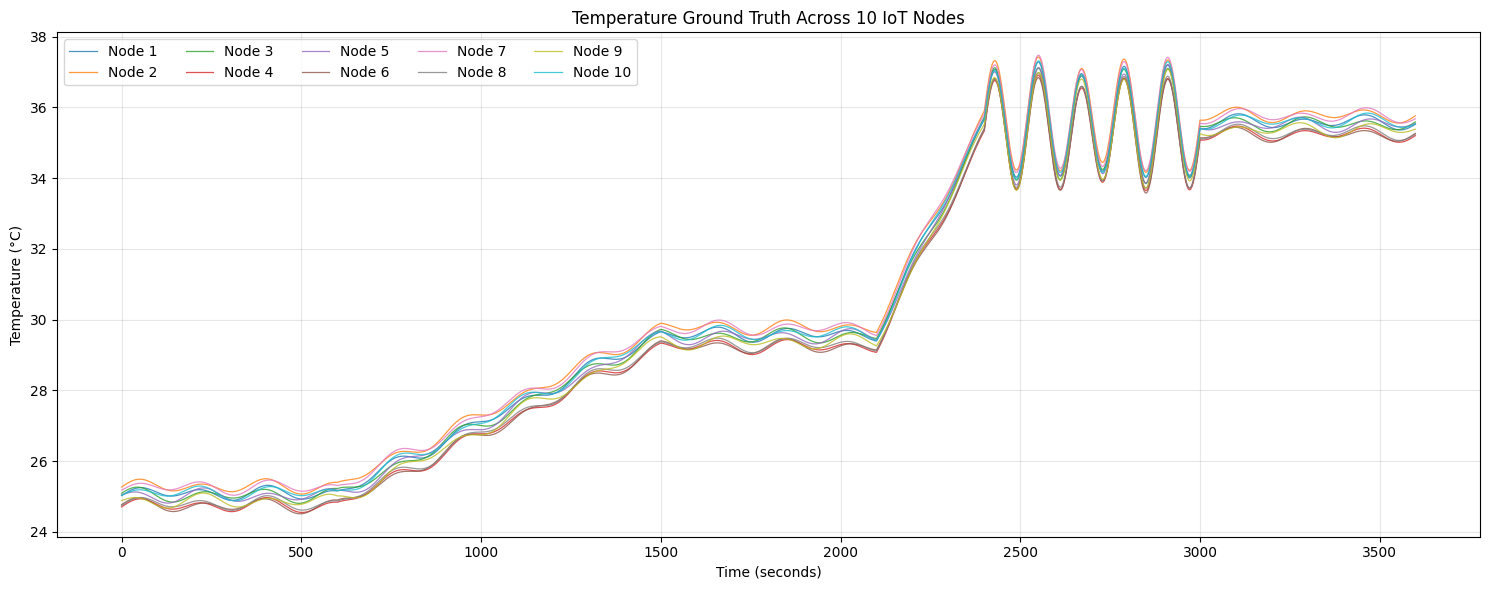

In [18]:

# =====================================================
# TEMPERATURE COMPARISON ACROSS ALL 10 NODES
# =====================================================

plt.figure(figsize=(15, 6))

for node_id in range(1, TOTAL_SENSORS + 1):

    node_data = ground_truth_df[
        ground_truth_df["node_id"] == node_id
    ]

    plt.plot(
        node_data["time_seconds"],
        node_data["temperature_true"],
        linewidth=0.9,
        alpha=0.8,
        label=f"Node {node_id}"
    )

plt.title("Temperature Ground Truth Across 10 IoT Nodes")
plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.legend(ncol=5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# =====================================================
# PHASE 3.12: DATASET VALIDATION
# =====================================================

print("=" * 55)
print("DATASET VALIDATION REPORT")
print("=" * 55)

# 1. Record count
print("\n1. Total records:")
print(len(sensor_measurements_df))

# 2. Number of nodes
print("\n2. Unique sensor nodes:")
print(sensor_measurements_df["node_id"].nunique())

# 3. Missing values
print("\n3. Missing values:")
print(sensor_measurements_df.isnull().sum())

# 4. Duplicate timestamps per node
duplicates = sensor_measurements_df.duplicated(
    subset=["node_id", "time_seconds"]
).sum()

print("\n4. Duplicate node-timestamp records:")
print(duplicates)

# 5. Humidity validity
humidity_valid = (
    sensor_measurements_df["humidity_true"].between(0, 100).all()
    and
    sensor_measurements_df["humidity_measured"].between(0, 100).all()
)

print("\n5. Humidity values within 0-100%:")
print(humidity_valid)

# 6. Measurement noise statistics
temp_error = (
    sensor_measurements_df["temperature_measured"]
    - sensor_measurements_df["temperature_true"]
)

humidity_error = (
    sensor_measurements_df["humidity_measured"]
    - sensor_measurements_df["humidity_true"]
)

print("\n6. Actual measurement noise:")
print("Temperature noise STD:", round(temp_error.std(), 4))
print("Humidity noise STD:", round(humidity_error.std(), 4))

# 7. Final validation
validation_passed = (
    len(sensor_measurements_df) == 36000
    and sensor_measurements_df["node_id"].nunique() == 10
    and sensor_measurements_df.isnull().sum().sum() == 0
    and duplicates == 0
    and humidity_valid
)

print("\n" + "=" * 55)

if validation_passed:
    print("DATASET STRUCTURAL VALIDATION PASSED")
else:
    print("DATASET VALIDATION FAILED - INVESTIGATE ERRORS")

print("=" * 55)


DATASET VALIDATION REPORT

1. Total records:
36000

2. Unique sensor nodes:
10

3. Missing values:
time_seconds            0
node_id                 0
temperature_true        0
humidity_true           0
temperature_measured    0
humidity_measured       0
scenario                0
event_active            0
dtype: int64

4. Duplicate node-timestamp records:
0

5. Humidity values within 0-100%:
True

6. Actual measurement noise:
Temperature noise STD: 0.1506
Humidity noise STD: 0.6017

DATASET STRUCTURAL VALIDATION PASSED


In [20]:

# =====================================================
# PHASE 3.13: PREPARE FINAL DATASETS
# =====================================================

# Add environmental scenario labels to ground truth
ground_truth_df["scenario"] = (
    ground_truth_df["time_seconds"].apply(classify_environment)
)

ground_truth_df["event_active"] = (
    (
        ground_truth_df["time_seconds"] >= 2100
    )
    &
    (
        ground_truth_df["time_seconds"] < 2400
    )
).astype(int)

# Select and organize ground-truth columns
ground_truth_df = ground_truth_df[
    [
        "time_seconds",
        "node_id",
        "temperature_true",
        "humidity_true",
        "scenario",
        "event_active"
    ]
]

# Organize sensor measurement columns
sensor_measurements_df = sensor_measurements_df[
    [
        "time_seconds",
        "node_id",
        "temperature_true",
        "temperature_measured",
        "humidity_true",
        "humidity_measured",
        "scenario",
        "event_active"
    ]
]

print("Both datasets prepared successfully.")

print("\nGround truth:")
display(ground_truth_df.head())

print("\nSensor measurements:")
display(sensor_measurements_df.head())


Both datasets prepared successfully.

Ground truth:


,time_seconds,node_id,temperature_true,humidity_true,scenario,event_active
0,0,1,25.029327,63.765991,Stable,0
1,1,1,25.035632,63.784558,Stable,0
2,2,1,25.041958,63.803171,Stable,0
3,3,1,25.048297,63.821813,Stable,0
4,4,1,25.054642,63.840469,Stable,0



Sensor measurements:


,time_seconds,node_id,temperature_true,temperature_measured,humidity_true,humidity_measured,scenario,event_active
0,0,1,25.029327,25.350574,63.765991,63.151837,Stable,0
1,1,1,25.035632,24.974670,63.784558,64.474635,Stable,0
2,2,1,25.041958,24.965121,63.803171,62.912562,Stable,0
3,3,1,25.048297,24.926231,63.821813,63.315618,Stable,0
4,4,1,25.054642,25.147039,63.840469,62.862989,Stable,0


In [21]:

# =====================================================
# CREATE DATASET STORAGE DIRECTORY
# =====================================================

import os

DATASET_PATH = "/content/datasets"

os.makedirs(DATASET_PATH, exist_ok=True)

print("Dataset directory created:")
print(DATASET_PATH)


Dataset directory created:
/content/datasets


In [22]:

# =====================================================
# EXPORT DATASETS
# =====================================================

ground_truth_file = os.path.join(
    DATASET_PATH,
    "ground_truth.csv"
)

sensor_measurements_file = os.path.join(
    DATASET_PATH,
    "sensor_measurements.csv"
)

ground_truth_df.to_csv(
    ground_truth_file,
    index=False
)

sensor_measurements_df.to_csv(
    sensor_measurements_file,
    index=False
)

print("DATASETS EXPORTED SUCCESSFULLY")

print("\nGround truth:")
print(ground_truth_file)

print("\nSensor measurements:")
print(sensor_measurements_file)

print("\nFile sizes:")

print(
    "Ground truth:",
    round(os.path.getsize(ground_truth_file) / 1024, 2),
    "KB"
)

print(
    "Sensor measurements:",
    round(os.path.getsize(sensor_measurements_file) / 1024, 2),
    "KB"
)


DATASETS EXPORTED SUCCESSFULLY

Ground truth:
/content/datasets/ground_truth.csv

Sensor measurements:
/content/datasets/sensor_measurements.csv

File sizes:
Ground truth: 1956.06 KB
Sensor measurements: 3242.66 KB


In [23]:

# Download both datasets to your computer

from google.colab import files

files.download(ground_truth_file)
files.download(sensor_measurements_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>